# AlexNet 2012 on Tiny ImageNet

Reproducing AlexNet (Krizhevsky et al., 2012), adapting, training and bechmarking it on Tiny ImageNet 64x64.

In [11]:
# Standard library
import os
import shutil
import time
import urllib.request
import zipfile

# Third-party
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.backends.cudnn as cudnn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from pathlib import Path
from lightning.pytorch.callbacks import ModelCheckpoint

In [12]:
URL       = "http://cs231n.stanford.edu/tiny-imagenet-200.zip"
DATA_ROOT = "data"
ZIP_PATH  = os.path.join(DATA_ROOT, "tiny-imagenet-200.zip")
DATA_DIR  = os.path.join(DATA_ROOT, "tiny-imagenet-200")

NUM_CLASSES = 200
NUM_EPOCHS  = 60
LR          = 0.02      # linearly scaled from paper: LR=0.01 BS=128
BATCH_SIZE  = 256
WEIGHT_DECAY = 5e-4
MOMENTUM    = 0.9
SEED        = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

### TinyImagenet Dataset

In [13]:
if not (os.path.isdir(DATA_DIR) and os.listdir(DATA_DIR)):
    os.makedirs(DATA_ROOT, exist_ok=True)
    print("Downloading Tiny ImageNet...")
    urllib.request.urlretrieve(URL, ZIP_PATH + ".part")
    os.replace(ZIP_PATH + ".part", ZIP_PATH)

    print("Extracting...")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_ROOT)

    os.remove(ZIP_PATH)
    print("Done:", DATA_DIR)

# torchvision.datasets.ImageFolder needs one subfolder per class.
# Tiny ImageNet has its train folder structured that way,
# but the val one is flat with a val_annotations.txt
val = os.path.join(DATA_DIR, "val")
if os.path.isdir(os.path.join(val, "images")):
    for line in open(os.path.join(val, "val_annotations.txt")):
        name, cls, *_ = line.strip().split("\t")
        os.makedirs(os.path.join(val, cls), exist_ok=True)
        shutil.move(os.path.join(val, "images", name), os.path.join(val, cls, name))
    shutil.rmtree(os.path.join(val, "images"))

### Transforms

In [14]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomCrop(64, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

### Datasets & DataLoaders

In [15]:
train_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_transform)
val_dataset   = datasets.ImageFolder(os.path.join(DATA_DIR, "val"),   transform=val_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=12, pin_memory=True, prefetch_factor=4, persistent_workers=True,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=4, pin_memory=True, prefetch_factor=4, persistent_workers=True,
)

print(f"train: {len(train_dataset)} imgs, {len(train_loader)} batches")
print(f"val:   {len(val_dataset)} imgs, {len(val_loader)} batches")

train: 100000 imgs, 391 batches
val:   10000 imgs, 40 batches


### Original* AlexNet 2012
*: The original paper effectively split conv layers between 2 GPUs due to hardware constraints at the time. Furthermore, it applied additional data-augmentation techniques to its input data, like PCA. It is also important to note that the original architecture was not made in pytorch but raw cuda. The vanilla architecture presented here is thus very close to the true original, but not exactly.

In [ ]:
class OriginalAlexNet(nn.Module):
    
    """
    Vanilla AlexNet 2012 with original conv schedule, designed for 224x224.

    Spatial trajectory:
        224 -> 55 -> 27 -> 27 -> 13 -> 13 -> 13 -> 6   (original paper input)
         64 -> 15 ->  7 ->  7 ->  3 ->  3 ->  3 -> 1   (Tiny ImageNet input)

    At 64x64 the trunk produces a 1x1 map, so AdaptiveAvgPool2d((6,6))
    broadcasts that single vector 36x into the first FC. The 9216-dim
    FC input is therefore nominally faithful to the paper but rank-redundant
    (only 256 values are unique).
    """

    def __init__(self, num_classes: int = NUM_CLASSES):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(96, 256, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(256, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        # 256 x 6 x 6 = 9216
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))

        self.classifier = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

### AlexNet 2012 adapted to Tiny Imagenet

In [ ]:
class AlexNet(nn.Module):

    """Adapted AlexNet 2012, designed for 64x64.

    The paper conv schedule (for 224x224) collapses 64x64 to a 1x1
    feature map before the FC head, which leaves the 9216-dim FC input
    rank-redundant: 36 copies of a 256-vector, roughly 37M wasted parameters.
    We reduce the stem's downsampling so the trunk produces a real 6x6 map at 64x64.

    Deviations from the paper:
        conv1: stride 4 -> 2   (11x11x3, 96 channels, padding 2)
        pool1: stride 2 -> 1   (3x3 maxpool)

    Spatial trajectories:
        paper 224x224:  224 -> 55 -> 27 -> 27 -> 13 -> 13 -> 13 ->> 6
        paper 64x64:     64 -> 15 ->  7 ->  7 ->  3 ->  3 ->  3 -> 1  (broadcast)
        adapted 64x64:   64 -> 29 -> 27 -> 27 -> 13 -> 13 -> 13 -> 6  (real)

    Channel counts, kernel sizes, LRN, dropout, and the FC head are identical to the paper.
    Cost: roughly 7x more conv FLOPs than the paper's schedule at 64x64;
    benefit: the FC head sees 36 distinct spatial positions per channel instead of 36 copies of one. We expect higher accuracy.
    """

    def __init__(self, num_classes: int = NUM_CLASSES):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=2, padding=2),  # 64 -> 29
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),
            
            nn.MaxPool2d(kernel_size=3, stride=1),                  # 29 -> 27

            nn.Conv2d(96, 256, kernel_size=5, padding=2),           # 27 -> 27
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),

            nn.MaxPool2d(kernel_size=3, stride=2),                  # 27 -> 13

            nn.Conv2d(256, 384, kernel_size=3, padding=1),          # 13 -> 13
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 384, kernel_size=3, padding=1),          # 13 -> 13
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),          # 13 -> 13
            nn.ReLU(inplace=True),

            nn.MaxPool2d(kernel_size=3, stride=2),                  # 13 -> 6
        )

        # Uncomment to accept arbitrary input sizes.
        # The pool will reshape whatever the trunk produces into 6x6 before the FC.
        # self.avgpool = nn.AdaptiveAvgPool2d((6, 6))

        self.classifier = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096),   # FC1: 9216 -> 4096
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        # x = self.avgpool(x)   # uncomment with the avgpool
        x = torch.flatten(x, 1)
        return self.classifier(x)

### Training

In [ ]:
import lightning as L
import torchmetrics

class LitAlexNet(L.LightningModule):
    def __init__(self, model_cls, num_classes, lr, momentum, weight_decay, max_epochs):
        super().__init__()
        self.save_hyperparameters(ignore=["model_cls"])
        self.net = model_cls(num_classes=num_classes)
        self.net = torch.compile(self.net)
        self.criterion = nn.CrossEntropyLoss()
        self.history = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}

        self.train_acc  = torchmetrics.classification.Accuracy(
            task="multiclass", num_classes=num_classes)
        self.val_acc    = torchmetrics.classification.Accuracy(
            task="multiclass", num_classes=num_classes)
        self.train_loss = torchmetrics.MeanMetric()
        self.val_loss   = torchmetrics.MeanMetric()

    def forward(self, x):
        return self.net(x)

    def _shared_step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)
        getattr(self, f"{stage}_acc")(logits, y)
        getattr(self, f"{stage}_loss")(loss, weight=x.size(0))
        self.log(f"{stage}_loss", getattr(self, f"{stage}_loss"), on_epoch=True)
        self.log(f"{stage}_acc",  getattr(self, f"{stage}_acc"),  on_epoch=True)
        return loss

    def training_step(self, batch, _):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, _):
        return self._shared_step(batch, "val")

    def on_validation_epoch_end(self):
        if self.trainer.sanity_checking:
            return
        m  = self.trainer.callback_metrics
        tl, ta = m["train_loss"].item(), m["train_acc"].item() * 100
        vl, va = m["val_loss"].item(),   m["val_acc"].item() * 100
        self.history["train_loss"].append(tl)
        self.history["train_acc"].append(ta)
        self.history["val_loss"].append(vl)
        self.history["val_acc"].append(va)
        e = self.trainer.current_epoch + 1
        print(f"Epoch {e:2d}/{self.trainer.max_epochs} | "
              f"Train {tl:.4f} {ta:5.2f}% | Val {vl:.4f} {va:5.2f}%")

    def configure_optimizers(self):
        opt = optim.SGD(
            self.parameters(),
            lr=self.hparams.lr,
            momentum=self.hparams.momentum,
            weight_decay=self.hparams.weight_decay
        )
        
        return {"optimizer": opt,
                "lr_scheduler": optim.lr_scheduler.CosineAnnealingLR(
                    opt, T_max=self.hparams.max_epochs)}
    
    def on_save_checkpoint(self, checkpoint):
        checkpoint["history"] = self.history

    def on_load_checkpoint(self, checkpoint):
        self.history = checkpoint.get("history", self.history)

In [19]:
ckpt = Path("checkpoints/original/last.ckpt")

if ckpt.exists():
    model_original = LitAlexNet.load_from_checkpoint(
        ckpt,
        model_cls=OriginalAlexNet,
        map_location="cpu" # change to GPU to run inference
    )
else:
    model_original = LitAlexNet(OriginalAlexNet, NUM_CLASSES, LR, MOMENTUM, WEIGHT_DECAY, NUM_EPOCHS)
    
    trainer_original = L.Trainer(
        max_epochs=NUM_EPOCHS,
        accelerator="gpu",
        devices=1,
        precision="16-mixed",
        callbacks=[ModelCheckpoint(dirpath=ckpt.parent, save_last=True)],
        enable_model_summary=False,
        enable_progress_bar=False,
    )
    
    trainer_original.fit(model_original, train_dataloaders=train_loader, val_dataloaders=val_loader)

history_original = model_original.history
print(f"Original - best train_loss={min(history_original['train_loss']):.4f}, "
      f"best val_loss={min(history_original['val_loss']):.4f}, "
      f"best val_acc={max(history_original['val_acc']):.2f}%")

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Epoch  1/60 | Train 5.2994  1.25% | Val 5.2981  0.50%
Epoch  2/60 | Train 5.2396  0.63% | Val 5.2502  0.74%
Epoch  3/60 | Train 5.0409  0.63% | Val 5.0903  1.15%
Epoch  4/60 | Train 4.8710  3.75% | Val 4.8937  2.35%
Epoch  5/60 | Train 4.9486  2.50% | Val 4.8415  2.25%
Epoch  6/60 | Train 4.6976  5.62% | Val 4.5708  4.21%
Epoch  7/60 | Train 4.3911  9.38% | Val 4.4052  6.83%
Epoch  8/60 | Train 4.3093  7.50% | Val 4.1441 10.18%
Epoch  9/60 | Train 3.9473 14.37% | Val 4.0873 10.64%
Epoch 10/60 | Train 4.0925  9.38% | Val 3.9613 12.59%
Epoch 11/60 | Train 3.6025 16.88% | Val 3.8516 14.89%
Epoch 12/60 | Train 3.8403 16.88% | Val 3.7352 16.70%
Epoch 13/60 | Train 3.5537 18.75% | Val 3.6904 17.66%
Epoch 14/60 | Train 3.5975 20.00% | Val 3.6063 19.10%
Epoch 15/60 | Train 3.4729 16.88% | Val 3.5120 21.33%
Epoch 16/60 | Train 3.3227 17.50% | Val 3.3696 24.22%
Epoch 17/60 | Train 3.2697 23.75% | Val 3.3460 24.25%
Epoch 18/60 | Train 3.1925 28.75% | Val 3.2420 25.92%
Epoch 19/60 | Train 3.1304 2

`Trainer.fit` stopped: `max_epochs=60` reached.


Original - best train_loss=0.4352, best val_loss=2.9979, best val_acc=34.07%


In [20]:
ckpt_path = Path("checkpoints/adapted/last.ckpt")

if ckpt_path.exists():
    model_adapted = LitAlexNet.load_from_checkpoint(
        ckpt_path,
        model_cls=AlexNet,
        map_location="cpu", # change to GPU to run inference
    )
else:
    model_adapted = LitAlexNet(AlexNet, NUM_CLASSES, LR, MOMENTUM, WEIGHT_DECAY, NUM_EPOCHS)

    trainer_adapted = L.Trainer(
        max_epochs=NUM_EPOCHS,
        accelerator="gpu",
        devices=1,
        precision="16-mixed",
        callbacks=[ModelCheckpoint(dirpath="checkpoints/adapted", save_last=True)],
        enable_model_summary=False,
        enable_progress_bar=False,
    )
    
    trainer_adapted.fit(model_adapted, train_dataloaders=train_loader, val_dataloaders=val_loader)

history_adapted = model_adapted.history
print(f"Adapted - best train_loss={min(history_original['train_loss']):.4f}, "
      f"best val_loss={min(history_original['val_loss']):.4f}, "
      f"best val_acc={max(history_original['val_acc']):.2f}%")

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Epoch  1/60 | Train 5.2980  0.00% | Val 5.2960  0.76%
Epoch  2/60 | Train 5.1247  0.00% | Val 5.0982  1.54%
Epoch  3/60 | Train 4.8463  1.88% | Val 4.8804  2.96%
Epoch  4/60 | Train 4.6919  5.62% | Val 4.4948  6.68%
Epoch  5/60 | Train 4.2857  5.62% | Val 4.1039 11.95%
Epoch  6/60 | Train 4.1193 10.00% | Val 3.9210 14.84%
Epoch  7/60 | Train 3.8334 20.62% | Val 3.7644 16.88%
Epoch  8/60 | Train 3.7912 15.00% | Val 3.4859 21.62%
Epoch  9/60 | Train 3.5237 21.25% | Val 3.3228 24.38%
Epoch 10/60 | Train 3.1159 28.12% | Val 3.2128 27.08%
Epoch 11/60 | Train 3.1663 29.37% | Val 3.1479 28.24%
Epoch 12/60 | Train 3.1287 25.62% | Val 2.9912 31.01%
Epoch 13/60 | Train 2.9179 32.50% | Val 2.8396 34.23%
Epoch 14/60 | Train 3.0499 31.25% | Val 2.8561 33.25%
Epoch 15/60 | Train 2.6007 36.25% | Val 2.7162 36.84%
Epoch 16/60 | Train 2.8638 35.62% | Val 2.6896 37.00%
Epoch 17/60 | Train 2.3389 39.38% | Val 2.6229 38.54%
Epoch 18/60 | Train 2.4620 36.88% | Val 2.6033 39.45%
Epoch 19/60 | Train 1.9487 5

`Trainer.fit` stopped: `max_epochs=60` reached.


Adapted - best train_loss=0.4352, best val_loss=2.9979, best val_acc=34.07%


### Loss & Accuracy Comparison

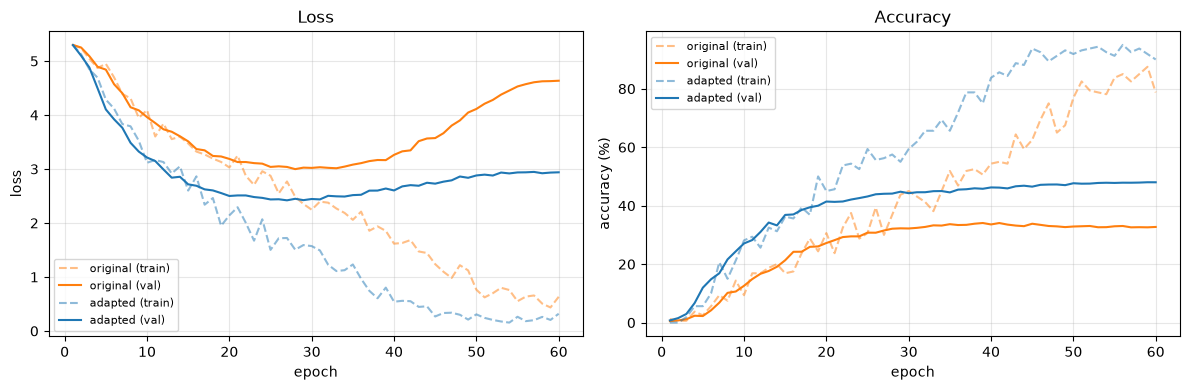

Original best val: 34.07%
Adapted  best val: 48.01%
Gap:               13.94 pp


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, NUM_EPOCHS + 1)

ax1.plot(epochs, history_original["train_loss"], "--", color="C1", alpha=0.5, label="original (train)")
ax1.plot(epochs, history_original["val_loss"],         color="C1",            label="original (val)")
ax1.plot(epochs, history_adapted["train_loss"],  "--", color="C0", alpha=0.5, label="adapted (train)")
ax1.plot(epochs, history_adapted["val_loss"],          color="C0",            label="adapted (val)")
ax1.set(xlabel="epoch", ylabel="loss", title="Loss")
ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

ax2.plot(epochs, history_original["train_acc"], "--", color="C1", alpha=0.5, label="original (train)")
ax2.plot(epochs, history_original["val_acc"],         color="C1",            label="original (val)")
ax2.plot(epochs, history_adapted["train_acc"],  "--", color="C0", alpha=0.5, label="adapted (train)")
ax2.plot(epochs, history_adapted["val_acc"],          color="C0",            label="adapted (val)")
ax2.set(xlabel="epoch", ylabel="accuracy (%)", title="Accuracy")
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# absolute accuracy gap between the two models
print(f"Original best val: {max(history_original['val_acc']):.2f}%")
print(f"Adapted  best val: {max(history_adapted['val_acc']):.2f}%")
print(f"Gap:               {max(history_adapted['val_acc']) - max(history_original['val_acc']):.2f} pp")